## Here, i want to try and calculate the temperature tendency that radiation brings into play

In [68]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [11]:
flex_out = xr.open_dataset('/jetfs/scratch/gbrack/flexpart_output/rad_interpolating_testrun/grid_time_20150510000000.nc')
rad = xr.open_mfdataset('/jetfs/scratch/gbrack/MSC/rad_data/2015/05/TMTTRAD_*.nc')

In [12]:
flex_out

<xarray.Dataset> Size: 585MB
Dimensions:     (time: 216, longitude: 420, latitude: 230, height: 7,
                 numpoint: 1, numspec: 1, nageclass: 1, pointspec: 1)
Coordinates:
  * time        (time) datetime64[ns] 2kB 2015-05-09T23:00:00 ... 2015-05-01
  * longitude   (longitude) float32 2kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
  * latitude    (latitude) float32 920B -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
  * height      (height) float32 28B 100.0 500.0 1e+03 2e+03 3e+03 5e+03 5e+04
Dimensions without coordinates: numpoint, numspec, nageclass, pointspec
Data variables: (12/15)
    RELCOM      (numpoint) |S45 45B ...
    RELLNG1     (numpoint) float32 4B ...
    RELLNG2     (numpoint) float32 4B ...
    RELLAT1     (numpoint) float32 4B ...
    RELLAT2     (numpoint) float32 4B ...
    RELZZ1      (numpoint) float32 4B ...
    ...          ...
    RELEND      (numpoint) timedelta64[ns] 8B ...
    RELPART     (numpoint) int32 4B ...
    RELXMASS    (numspec, numpoint) float32 4B ...
    LAGE        (nageclass) timedelta64[ns] 8B ...
    ORO         (latitude, longitude) int32 386kB ...
    spec001_mr  (nageclass, pointspec, time, height, latitude, longitude) float32 584MB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    dace3af Mon Nov 24 10:17:47 2025 +0100
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-10-23 10:40 +0200  created by gbrack on jet1...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          2
    sfc_only:               0
    linit_cond:             2

In [13]:
rad

<xarray.Dataset> Size: 169GB
Dimensions:      (valid_time: 595, model_level: 137, latitude: 361,
                  longitude: 720)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 5kB 2015-05-01 ... 2015-05-25T18...
  * model_level  (model_level) float64 1kB 1.0 2.0 3.0 4.0 ... 135.0 136.0 137.0
  * latitude     (latitude) float64 3kB 90.0 89.5 89.0 ... -89.0 -89.5 -90.0
  * longitude    (longitude) float64 6kB -179.5 -179.0 -178.5 ... 179.5 180.0
    expver       (valid_time) <U4 10kB dask.array<chunksize=(7,), meta=np.ndarray>
Data variables:
    avg_ttswr    (valid_time, model_level, latitude, longitude) float32 85GB dask.array<chunksize=(2, 35, 91, 180), meta=np.ndarray>
    avg_ttlwr    (valid_time, model_level, latitude, longitude) float32 85GB dask.array<chunksize=(2, 35, 91, 180), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-22T05:29 GRIB to CDM+CF via cfgrib-0.9.1...

In [14]:
print(flex_out["spec001_mr"])
print(flex_out["spec001_mr"].attrs)

print(rad["avg_ttswr"].attrs)
print(rad["avg_ttlwr"].attrs)

print(flex_out["height"].attrs)
print(list(flex_out.data_vars))

<xarray.DataArray 'spec001_mr' (nageclass: 1, pointspec: 1, time: 216,
                                height: 7, latitude: 230, longitude: 420)> Size: 584MB
[146059200 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 2kB 2015-05-09T23:00:00 ... 2015-05-01
  * longitude  (longitude) float32 2kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
  * latitude   (latitude) float32 920B -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
  * height     (height) float32 28B 100.0 500.0 1e+03 2e+03 3e+03 5e+03 5e+04
Dimensions without coordinates: nageclass, pointspec
Attributes:
    units:        s m3 kg-1
    long_name:    AIRTRACER
    decay:        -999.9
    weightmolar:  29.0
{'units': 's m3 kg-1', 'long_name': 'AIRTRACER', 'decay': -999.9, 'weightmolar': 29.0}
{'GRIB_paramId': 235001, 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': 259920, 'GRIB_typeOfLevel': 'hybrid', 'GRIB_stepUnits': 1, 'GRIB_stepType': 'avg', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': 0, 'GRIB_NV': 27

In [29]:
def open_met_parameter(param_id):
    return xr.open_dataset(
        metfile,
        engine="cfgrib",
        backend_kwargs={
            "filter_by_keys": {"paramId": param_id},
            "indexpath": "",
        },
    )

met_t = open_met_parameter(130)
met_q = open_met_parameter(133)
met_sp = open_met_parameter(134)
met_z = open_met_parameter(129)

met = xr.merge(
    [
        met_t,
        met_q,
        met_sp.drop_vars("surface", errors="ignore"),
        met_z.drop_vars("surface", errors="ignore"),
    ], 
    join="exact")

In [30]:
with open(metfile, "rb") as f:
    while True:
        gid = eccodes.codes_grib_new_from_file(f)
        if gid is None:
            raise ValueError("Kein Temperaturfeld gefunden")

        try:
            if eccodes.codes_get(gid, "paramId") == 130:
                pv = np.asarray(eccodes.codes_get_array(gid, "pv"))
                break
        finally:
            eccodes.codes_release(gid)

a_half = pv[:138]
b_half = pv[138:]

print("Variablen:", list(met.data_vars))
print("Hybridkoeffizienten:", a_half.shape, b_half.shape)

Variablen: ['t', 'q', 'sp', 'z']
Hybridkoeffizienten: (138,) (138,)


In [38]:
met = met.sortby("hybrid")

np.testing.assert_array_equal(
    met.hybrid.values,
    np.arange(1, 138)
)

# Druck auf den vollen Modelllevels
a_full = xr.DataArray(
    0.5 * (a_half[:-1] + a_half[1:]),
    dims=["hybrid"],
    coords={"hybrid": met.hybrid},
)

b_full = xr.DataArray(
    0.5 * (b_half[:-1] + b_half[1:]),
    dims=["hybrid"],
    coords={"hybrid": met.hybrid},
)

pressure = (a_full + b_full * met.sp).transpose("hybrid", "latitude", "longitude")
pressure.attrs = {"long_name": "Model-Level Pressure", "units": "Pa"}

Rd = 287.05  # J/(kg*K)
virtual_temp = met.t * (1 + 0.609133 * met.q)

density = pressure / (Rd * virtual_temp)
density.attrs = {"long_name": "Air Density", "units": "kg/m^3"}

In [57]:
def calculate_level_heights(met, a_half, b_half):
    met = met.sortby("hybrid")

    g0 = 9.80665
    Rd = 287.06

    temperature = met.t.values
    humidity = met.q.values
    surface_pressure = met.sp.values

    virtual_temperature = temperature * (1 + 0.609133 * humidity)

    pressure_half = a_half + b_half * surface_pressure

    height_full = np.empty(137)
    height_half = np.empty(138)
    height_half[137] = 0.0
    geopotential_half = 0.0

    for level in range(137, 0, -1):
        p_lower = pressure_half[level]
        p_upper = pressure_half[level - 1]
        rt = Rd * virtual_temperature[level - 1]

        if level == 1:
            dlog_p = np.log(p_lower / 0.1)
            alpha = np.log(2.0)
        else:
            dlog_p = np.log(p_lower / p_upper)
            alpha = 1.0 - (
                p_upper / (p_lower - p_upper) * dlog_p
            )

        geopotential_full = geopotential_half + rt * alpha
        height_full[level - 1] = geopotential_full / g0
        geopotential_half = geopotential_half + rt * dlog_p
        height_half[level - 1] = geopotential_half / g0

    height_half[0] = np.inf

    return height_full, height_half

In [ ]:
met_delhi = met.sel(
    latitude=28.6,
    longitude=77.2,
    method="nearest",
)

heights_delhi, boundaries_delhi = calculate_level_heights(
    met_delhi, a_half, b_half
)

In [62]:
print("Untere Grenze:", boundaries_delhi[137])
print("Modelllevel:  ", heights_delhi[136])
print("Obere Grenze:", boundaries_delhi[136])

Untere Grenze: 0.0
Modelllevel:   10.390234968934122
Obere Grenze: 20.788690802421065


In [61]:
for level in range(128, 138):
    print(f"Level {level}: Height = {heights_delhi[level - 1]:.2f} m")

Level 128: Height = 297.96 m
Level 129: Height = 253.54 m
Level 130: Height = 212.88 m
Level 131: Height = 175.69 m
Level 132: Height = 141.67 m
Level 133: Height = 110.54 m
Level 134: Height = 82.06 m
Level 135: Height = 56.00 m
Level 136: Height = 32.17 m
Level 137: Height = 10.39 m


In [63]:
era_lower = boundaries_delhi[1:]
era_upper = boundaries_delhi[:-1]

bottom = 0.0
top = 100.0

overlap = np.maximum(
    0.0,
    np.minimum(era_upper, top) - np.maximum(era_lower, bottom),
)

In [64]:
for level in range (1, 138):
    thickness = overlap[level - 1]

    if thickness > 0:
        print(f"Level {level}: {thickness:.2f} m Überlappung")

print(f"Summe: {overlap.sum():.2f} m")

Level 133: 4.33 m Überlappung
Level 134: 27.21 m Überlappung
Level 135: 24.90 m Überlappung
Level 136: 22.77 m Überlappung
Level 137: 20.79 m Überlappung
Summe: 100.00 m


In [65]:
weights = xr.DataArray(
    overlap / (top - bottom),
    dims="model_level",
    coords={"model_level": met_delhi.hybrid.values},
)

print("Summe der Gewichte:", weights.sum().item())

Summe der Gewichte: 1.0


In [66]:
rad_delhi = rad.sel(
    valid_time=met_delhi.valid_time.values,
    latitude=met_delhi.latitude.item(),
    longitude=met_delhi.longitude.item(),
)

<xarray.Dataset> Size: 2kB
Dimensions:      (model_level: 137)
Coordinates:
    valid_time   datetime64[ns] 8B 2015-05-01
  * model_level  (model_level) float64 1kB 1.0 2.0 3.0 4.0 ... 135.0 136.0 137.0
    latitude     float64 8B 28.5
    longitude    float64 8B 77.0
    expver       <U4 16B dask.array<chunksize=(), meta=np.ndarray>
Data variables:
    avg_ttswr    (model_level) float32 548B dask.array<chunksize=(35,), meta=np.ndarray>
    avg_ttlwr    (model_level) float32 548B dask.array<chunksize=(35,), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-22T05:29 GRIB to CDM+CF via cfgrib-0.9.1...

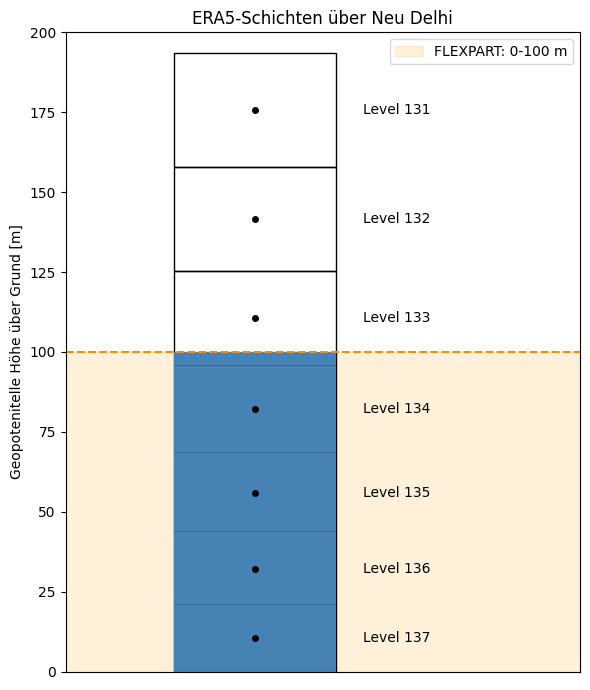

In [70]:
fig, ax = plt.subplots(1, 1, figsize=(6, 7))

ax.axhspan(
    bottom,
    top,
    color="orange",
    alpha=0.15,
    label="FLEXPART: 0-100 m"
)

for level in range(131, 138):
    i = level - 1

    lower = era_lower[i]
    upper = era_upper[i]

    ax.bar(
        0, upper - lower, 
        bottom=lower,
        width=0.6,
        facecolor="none",
        edgecolor="black",
    )

    if overlap[i] > 0:
        ax.bar(
            0, overlap[i], 
            bottom=max(lower, bottom),
            width=0.6, color="steelblue"
        )

    ax.plot(0, heights_delhi[i], "ko", markersize=4)

    ax.text(0.4, heights_delhi[i], f"Level {level}", va="center")

ax.axhline(top, color="darkorange", linestyle="--")
ax.set_ylim(0, 200)
ax.set_xlim(-0.7, 1.2)
ax.set_xticks([])
ax.set_ylabel("Geopotenitelle Höhe über Grund [m]")
ax.set_title("ERA5-Schichten über Neu Delhi")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

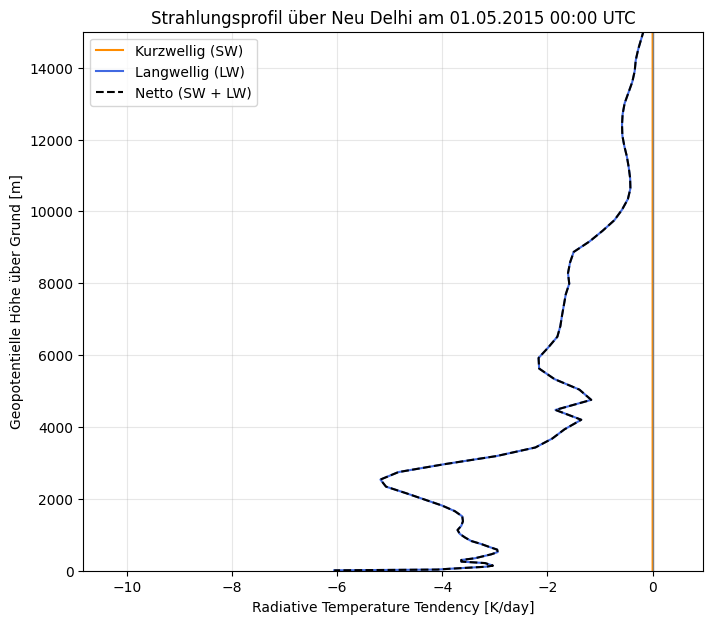

In [72]:
sw = rad_delhi.avg_ttswr.sel(
    model_level=met_delhi.hybrid.values
)
lw = rad_delhi.avg_ttlwr.sel(
    model_level=met_delhi.hybrid.values
)

seconds_per_day = 86400

fig, ax = plt.subplots(1, 1, figsize=(8, 7))

ax.plot(
    sw.values * seconds_per_day,
    heights_delhi,
    label="Kurzwellig (SW)",
    color="darkorange",
)

ax.plot(
    lw.values * seconds_per_day,
    heights_delhi,
    label="Langwellig (LW)",
    color="royalblue",
)

ax.plot(
    (sw + lw).values * seconds_per_day,
    heights_delhi,
    label="Netto (SW + LW)",
    color="black",
    linestyle="--",
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_ylim(0, 15000)
ax.set_xlabel("Radiative Temperature Tendency [K/day]")
ax.set_ylabel("Geopotentielle Höhe über Grund [m]")
ax.set_title("Strahlungsprofil über Neu Delhi am 01.05.2015 00:00 UTC")
ax.grid(alpha=0.3)
ax.legend()

